# Problem set 7

### Problem 1: Lagrange interpolation

The Lagrange interpolation polynomial of degree at most $n$ that passes through the set of points $(x_0, x_1), (x_1, y_1), \dots, (x_n, y_n)$ is the polynomial defined as
$$P(x) = \sum_{k=0}^{n} y_k L_k(x),$$
where
$$L_k(x) = \prod_{\substack{i=0 \\ i \neq k}}^{n} \frac{x - x_i}{x_k - x_i}.$$

#### Part 1 - Implement into code

Write a function `lagrange` that evaluates the Lagrange interpolation polynomial at a given point. See the specification below.

In [ ]:
def lagrange(x_points, y_points, x):
    """
    Evaluate Lagrange interpolation polynomial through points at x

    Parameters
    ----------
    x_points (list): List of x-coordinates of interpolating points,
                     without any duplicates
    y_points (list): List of y-coordinates of interpolating points, 
                     of equal length as x_points
    x (float):       Value at which the polynomial is evaluated

    Returns
    -------
    (float):         Value of polynomial evaluated at x: P(x)

    Example
    -------
    >>> x_points = [0, 1, 2, 3, 4, 5]
    >>> y_points = [0.0, 0.8, 0.9, 0.1, -0.8, -1.0]
    >>> print(lagrange(x_points, y_points, 4.5)
    -1.01015625
    
    """

    # Your solution goes here
    L_k = []
    k = 0
    while len(L_k) < len(x_points):
        product = 1
        for i in range(len(x_points)):
            if i == k: 
                continue
            else: 
                product *= (x - x_points[i])/(x_points[k]-x_points[i])
        L_k.append(product)
        k+=1
    px = 0 
    for i in range(len(y_points)):
        px += y_points[i] * L_k[i]
    return px
                

In [52]:
# Example to test your function lagrange
x_points = [0, 1, 2, 3, 4, 5]
y_points = [0.0, 0.8, 0.9, 0.1, -0.8, -1.0]
print(lagrange(x_points, y_points, 4.5)) 

True
-1.01015625


#### Part 2 - Visualisation

Consider the points $(0, 0), (1, 0.8), (2, 0.9), (3, 0.1), (4, -0.8), (5, -1)$. Plot the interpolation polynomial that goes through these points. Overlay the original interpolation points on the graph to visually verify the interpolation. Use a smooth curve to represent the interpolation polynomial and the interpolation points with a distinct marker style. Plot the resulting polynomial over a the range of $x$-values in $[-1, 6]$. 

<center><img src="https://i.ibb.co/RbR0Tzn/lagrange.png"  width=500 border="0"></center>

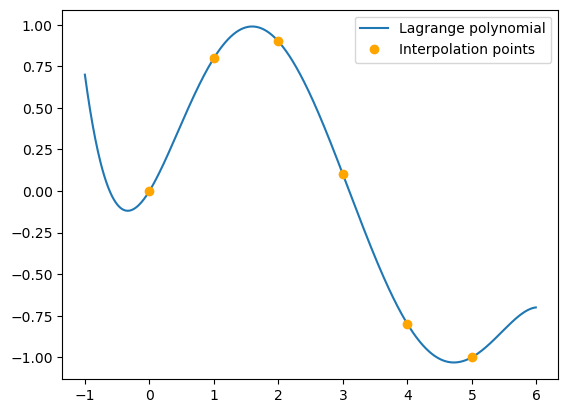

In [41]:
import matplotlib.pyplot as plt

x_points = [0, 1, 2, 3, 4, 5]
y_points = [0.0, 0.8, 0.9, 0.1, -0.8, -1.0]

# Your solution goes here
x = []
y = []
xval = -1
for i in range(700):
    x.append(xval)
    y.append(lagrange(x_points, y_points, xval))
    xval+=0.01

plt.plot(x,y)
plt.plot(x_points,y_points, marker = "o", color = "orange", linestyle = "None")
plt.legend(["Lagrange polynomial", "Interpolation points"])
plt.show()


#### Part 3 - Least squares polynomial

In addition to constructing and evaluating the Lagrange interpolation polynomial, you will now compute a least squares polynomial of degree 3 that best fits the given set of points. We will be using the built-in function `polyfit` from the `numpy` package, which computes the coefficients of the polynomial that minimizes the least squares error between the polynomial and the points. You can read in the [documentation](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html) how the function `polyfit` works, a bit of sample code has already been provided for you below.

Add to your previous plot the graph of the least squares polynomial of degree 3 for these points.

In [55]:
import numpy as np

x_points = [0, 1, 2, 3, 4, 5]
y_points = [0.0, 0.8, 0.9, 0.1, -0.8, -1.0]

p3 = np.polyfit(x_points, y_points, 3)

### Problem 2: Linear spline

The linear spline $s_L(x)$ that passes through the set of points $(x_1, y_1), (x_2, y_2), \dots, (x_n, y_n)$, with $x_1 < x_2 < \dots < x_n$ is defined by
$$s_L(x) = \frac{x - x_{i+1}}{x_i - x_{i+1}} f(x_{i}) + \frac{x - x_i}{x_{i+1} - x_i} f(x_{i+1}), \qquad \text{for $x \in [x_i, x_{i+1}]$}.$$

Write a function named `linear_spline` that evaluates the linear spline through a set of points. Your function should find the interval $[x_i, x_{i+1}]$ where $x$. It should also handle the cases where $x$ is smaller than $x_1$ or larger than $x_n$, by printing an error message `x is out of bounds` and returning `None`. 

In [68]:
def linear_spline(x_points, y_points, x):
    """
    Evaluate linear spline through points at x

    Parameters
    ----------
    x_points (list): Ordered list of x-coordinates of interpolating points,
                     where x1 < x2 < ... < xn
    y_points (list): List of y-coordinates of interpolating points, 
                     of equal length as x_points
    x (float):       Value at which the polynomial is evaluated

    Returns
    -------
    (float):         Value of linear spline evaluated at x: s(x)

    Example
    -------
    >>> x_points = [1, 2, 3, 4]
    >>> y_points = [2, 3, 5, 4]
    >>> linear_spline(x_points, y_points, 2.5)
    4
    >>> line_spline(x_points, y_points, 0.5)
    x is out of bounds
    
    """

    # Your solution goes here
    if x < x_points[0] or x > x_points[-1]:
        print("x is out of bounds")
        return 
    sl = 0
    for i in range(len(x_points)-1):
        if x >= x_points[i] and x <= x_points[i+1]:
            sl = ((x-x_points[i+1])*y_points[i])/(x_points[i] - x_points[i+1]) + ((x - x_points[i])*y_points[i+1])/(x_points[i+1] - x_points[i])
            return sl


In [76]:
x_points = [1, 2, 3, 4]
y_points = [2, 3, 5, 4]
print(linear_spline(x_points, y_points, 2.5))
print(linear_spline(x_points, y_points, 0.5))


4.0
x is out of bounds
None
